# AI-Powered Dynamic Ride Fare Prediction System

## 1. Project Overview

This project aims to predict ride fares using machine learning. It uses trip details such as pickup location, destination, cab type, distance, time, and weather conditions to estimate the ride fare.

The project combines ride and weather datasets, performs data preprocessing and feature engineering, and trains regression models to predict fares.

The final model is integrated into a web application built using FastAPI and React, allowing users to select locations and get an estimated fare.

## 2. Project Objectives

- Analyze ride-fare data and identify useful features.
- Combine ride data with weather information.
- Clean and preprocess the dataset.
- Perform feature engineering and prepare data for machine learning.
- Train and compare different regression models.
- Evaluate the final model using appropriate regression metrics.
- Use the trained model to predict ride fares through a web application.

## 3. Importing Libraries

The following Python libraries are imported for data analysis, statistical analysis, and visualization.

- **NumPy (`numpy`):** Used for numerical operations.
- **Pandas (`pandas`):** Used to load, process, and analyze datasets.
- **Matplotlib (`matplotlib.pyplot`):** Used to create graphs and visualizations.
- **Seaborn (`seaborn`):** Used to visualize data and identify patterns.
- **SciPy Stats (`scipy.stats`):** Used for statistical analysis.
- **Warnings:** Used to control warning messages during execution.

In [23]:
import numpy as n
import pandas as p
import matplotlib.pyplot as plt
import seaborn as s
import warnings
import scipy.stats as stats
warnings.filterwarnings("ignore")

## 4. Loading the Datasets

This project uses ride-fare data and weather data for analysis and fare prediction.

Both datasets are loaded into Pandas DataFrames for further processing and analysis.

## 5. Initial Data Inspection

The datasets are inspected to understand their structure, column names, data types, and overall size. This step helps identify the information available for analysis before preprocessing.

In [24]:
rides_df = p.read_csv(r"C:\Users\Pushpraj Pardeshi\Downloads\cab_rides.csv.zip")

In [25]:
ds2 = p.read_csv(r"C:\Users\Pushpraj Pardeshi\Downloads\weather.csv")

In [26]:
rides_df.shape

(693071, 10)

In [27]:
ds2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6276 entries, 0 to 6275
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   temp        6276 non-null   float64
 1   location    6276 non-null   object 
 2   clouds      6276 non-null   float64
 3   pressure    6276 non-null   float64
 4   rain        894 non-null    float64
 5   time_stamp  6276 non-null   int64  
 6   humidity    6276 non-null   float64
 7   wind        6276 non-null   float64
dtypes: float64(6), int64(1), object(1)
memory usage: 392.4+ KB


## 6. Data Cleaning and Missing Values

Data cleaning is an important step before training a machine learning model.

In this step, the datasets are checked for missing values and duplicate records. Missing values are handled to prepare the data for further analysis.

The data is also checked for consistency so that it can be used in the next stages of the machine learning workflow.

In [28]:
ds2["date_time"] = p.to_datetime(ds2["time_stamp"],unit="s")

In [29]:
ds2

,temp,location,clouds,pressure,rain,time_stamp,humidity,wind,date_time
0,42.42,Back Bay,1.00,1012.14,0.1228,1545003901,0.77,11.25,2018-12-16 23:45:01
1,42.43,Beacon Hill,1.00,1012.15,0.1846,1545003901,0.76,11.32,2018-12-16 23:45:01
2,42.50,Boston University,1.00,1012.15,0.1089,1545003901,0.76,11.07,2018-12-16 23:45:01
3,42.11,Fenway,1.00,1012.13,0.0969,1545003901,0.77,11.09,2018-12-16 23:45:01
4,43.13,Financial District,1.00,1012.14,0.1786,1545003901,0.75,11.49,2018-12-16 23:45:01
...,...,...,...,...,...,...,...,...,...
6271,44.72,North Station,0.89,1000.69,NaN,1543819974,0.96,1.52,2018-12-03 06:52:54
6272,44.85,Northeastern University,0.88,1000.71,NaN,1543819974,0.96,1.54,2018-12-03 06:52:54
6273,44.82,South Station,0.89,1000.70,NaN,1543819974,0.96,1.54,2018-12-03 06:52:54
6274,44.78,Theatre District,0.89,1000.70,NaN,1543819974,0.96,1.54,2018-12-03 06:52:54


In [30]:
ds2["hour_date"] = ds2["date_time"].dt.floor("h")

In [31]:
# Har ghante ke saare minute-level records ka average
ds2_clean = ds2.groupby(['location', 'hour_date']).agg({
    'temp': 'mean',
    'clouds': 'mean',
    'pressure': 'mean',
    'rain': 'mean',
    'humidity': 'mean',
    'wind': 'mean'
}).reset_index()

In [32]:
ds2_clean

,location,hour_date,temp,clouds,pressure,rain,humidity,wind
0,Back Bay,2018-11-26 03:00:00,41.040000,0.870000,1014.390000,NaN,0.920000,1.460000
1,Back Bay,2018-11-26 04:00:00,40.658000,0.894000,1014.008000,NaN,0.926000,2.646000
2,Back Bay,2018-11-26 05:00:00,40.561250,0.930000,1013.821250,NaN,0.921250,2.496250
3,Back Bay,2018-11-26 06:00:00,40.627333,0.990667,1014.196667,NaN,0.913333,1.350667
4,Back Bay,2018-11-26 07:00:00,41.137500,0.970000,1014.292500,NaN,0.920000,1.735000
...,...,...,...,...,...,...,...,...
3955,West End,2018-12-18 14:00:00,26.190000,0.480000,1010.120000,NaN,0.470000,13.890000
3956,West End,2018-12-18 15:00:00,27.220000,0.340000,1011.420000,NaN,0.460000,15.030000
3957,West End,2018-12-18 16:00:00,28.700000,0.310000,1011.480000,NaN,0.470000,14.600000
3958,West End,2018-12-18 17:00:00,30.050000,0.150000,1011.420000,NaN,0.460000,13.550000


In [33]:
ds2_clean.isnull().sum()

location        0
hour_date       0
temp            0
clouds          0
pressure        0
rain         3385
humidity        0
wind            0
dtype: int64

In [34]:
rides_df["source"].unique(),rides_df["destination"].unique()

(array(['Haymarket Square', 'Back Bay', 'North End', 'North Station',
        'Beacon Hill', 'Boston University', 'Fenway', 'South Station',
        'Theatre District', 'West End', 'Financial District',
        'Northeastern University'], dtype=object),
 array(['North Station', 'Northeastern University', 'West End',
        'Haymarket Square', 'South Station', 'Fenway', 'Theatre District',
        'Beacon Hill', 'Back Bay', 'North End', 'Financial District',
        'Boston University'], dtype=object))

In [35]:
rides_df

,distance,cab_type,time_stamp,destination,source,price,surge_multiplier,id,product_id,name
0,0.44,Lyft,1544952607890,North Station,Haymarket Square,5.0,1.0,424553bb-7174-41ea-aeb4-fe06d4f4b9d7,lyft_line,Shared
1,0.44,Lyft,1543284023677,North Station,Haymarket Square,11.0,1.0,4bd23055-6827-41c6-b23b-3c491f24e74d,lyft_premier,Lux
2,0.44,Lyft,1543366822198,North Station,Haymarket Square,7.0,1.0,981a3613-77af-4620-a42a-0c0866077d1e,lyft,Lyft
3,0.44,Lyft,1543553582749,North Station,Haymarket Square,26.0,1.0,c2d88af2-d278-4bfd-a8d0-29ca77cc5512,lyft_luxsuv,Lux Black XL
4,0.44,Lyft,1543463360223,North Station,Haymarket Square,9.0,1.0,e0126e1f-8ca9-4f2e-82b3-50505a09db9a,lyft_plus,Lyft XL
...,...,...,...,...,...,...,...,...,...,...
693066,1.00,Uber,1543708385534,North End,West End,13.0,1.0,616d3611-1820-450a-9845-a9ff304a4842,6f72dfc5-27f1-42e8-84db-ccc7a75f6969,UberXL
693067,1.00,Uber,1543708385534,North End,West End,9.5,1.0,633a3fc3-1f86-4b9e-9d48-2b7132112341,55c66225-fbe7-4fd5-9072-eab1ece5e23e,UberX
693068,1.00,Uber,1543708385534,North End,West End,NaN,1.0,64d451d0-639f-47a4-9b7c-6fd92fbd264f,8cf7e821-f0d3-49c6-8eba-e679c0ebcf6a,Taxi
693069,1.00,Uber,1543708385534,North End,West End,27.0,1.0,727e5f07-a96b-4ad1-a2c7-9abc3ad55b4e,6d318bcc-22a3-4af6-bddd-b409bfce1546,Black SUV


In [36]:
rides_df["date_time"] = p.to_datetime(rides_df["time_stamp"],unit="ms")

In [37]:
rides_df["hour_date"] = rides_df["date_time"].dt.floor("h")

In [38]:
merged_df = p.merge(
    rides_df, 
    ds2_clean, 
    left_on=['source', "hour_date"], 
    right_on=['location', 'hour_date'], 
    how='left'
)

In [39]:
merged_df

,distance,cab_type,time_stamp,destination,source,price,surge_multiplier,id,product_id,name,date_time,hour_date,location,temp,clouds,pressure,rain,humidity,wind
0,0.44,Lyft,1544952607890,North Station,Haymarket Square,5.0,1.0,424553bb-7174-41ea-aeb4-fe06d4f4b9d7,lyft_line,Shared,2018-12-16 09:30:07.890,2018-12-16 09:00:00,Haymarket Square,38.460,0.290000,1022.25,NaN,0.760000,7.68
1,0.44,Lyft,1543284023677,North Station,Haymarket Square,11.0,1.0,4bd23055-6827-41c6-b23b-3c491f24e74d,lyft_premier,Lux,2018-11-27 02:00:23.677,2018-11-27 02:00:00,Haymarket Square,44.065,0.995000,1002.88,0.106,0.895000,12.63
2,0.44,Lyft,1543366822198,North Station,Haymarket Square,7.0,1.0,981a3613-77af-4620-a42a-0c0866077d1e,lyft,Lyft,2018-11-28 01:00:22.198,2018-11-28 01:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0.44,Lyft,1543553582749,North Station,Haymarket Square,26.0,1.0,c2d88af2-d278-4bfd-a8d0-29ca77cc5512,lyft_luxsuv,Lux Black XL,2018-11-30 04:53:02.749,2018-11-30 04:00:00,Haymarket Square,35.080,0.000000,1013.71,NaN,0.700000,5.25
4,0.44,Lyft,1543463360223,North Station,Haymarket Square,9.0,1.0,e0126e1f-8ca9-4f2e-82b3-50505a09db9a,lyft_plus,Lyft XL,2018-11-29 03:49:20.223,2018-11-29 03:00:00,Haymarket Square,37.680,0.433333,998.42,NaN,0.706667,11.16
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
693066,1.00,Uber,1543708385534,North End,West End,13.0,1.0,616d3611-1820-450a-9845-a9ff304a4842,6f72dfc5-27f1-42e8-84db-ccc7a75f6969,UberXL,2018-12-01 23:53:05.534,2018-12-01 23:00:00,West End,36.690,0.410000,1023.64,NaN,0.760000,2.51
693067,1.00,Uber,1543708385534,North End,West End,9.5,1.0,633a3fc3-1f86-4b9e-9d48-2b7132112341,55c66225-fbe7-4fd5-9072-eab1ece5e23e,UberX,2018-12-01 23:53:05.534,2018-12-01 23:00:00,West End,36.690,0.410000,1023.64,NaN,0.760000,2.51
693068,1.00,Uber,1543708385534,North End,West End,NaN,1.0,64d451d0-639f-47a4-9b7c-6fd92fbd264f,8cf7e821-f0d3-49c6-8eba-e679c0ebcf6a,Taxi,2018-12-01 23:53:05.534,2018-12-01 23:00:00,West End,36.690,0.410000,1023.64,NaN,0.760000,2.51
693069,1.00,Uber,1543708385534,North End,West End,27.0,1.0,727e5f07-a96b-4ad1-a2c7-9abc3ad55b4e,6d318bcc-22a3-4af6-bddd-b409bfce1546,Black SUV,2018-12-01 23:53:05.534,2018-12-01 23:00:00,West End,36.690,0.410000,1023.64,NaN,0.760000,2.51


In [40]:
merged_df.head()

,distance,cab_type,time_stamp,destination,source,price,surge_multiplier,id,product_id,name,date_time,hour_date,location,temp,clouds,pressure,rain,humidity,wind
0,0.44,Lyft,1544952607890,North Station,Haymarket Square,5.0,1.0,424553bb-7174-41ea-aeb4-fe06d4f4b9d7,lyft_line,Shared,2018-12-16 09:30:07.890,2018-12-16 09:00:00,Haymarket Square,38.460,0.290000,1022.25,NaN,0.760000,7.68
1,0.44,Lyft,1543284023677,North Station,Haymarket Square,11.0,1.0,4bd23055-6827-41c6-b23b-3c491f24e74d,lyft_premier,Lux,2018-11-27 02:00:23.677,2018-11-27 02:00:00,Haymarket Square,44.065,0.995000,1002.88,0.106,0.895000,12.63
2,0.44,Lyft,1543366822198,North Station,Haymarket Square,7.0,1.0,981a3613-77af-4620-a42a-0c0866077d1e,lyft,Lyft,2018-11-28 01:00:22.198,2018-11-28 01:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0.44,Lyft,1543553582749,North Station,Haymarket Square,26.0,1.0,c2d88af2-d278-4bfd-a8d0-29ca77cc5512,lyft_luxsuv,Lux Black XL,2018-11-30 04:53:02.749,2018-11-30 04:00:00,Haymarket Square,35.080,0.000000,1013.71,NaN,0.700000,5.25
4,0.44,Lyft,1543463360223,North Station,Haymarket Square,9.0,1.0,e0126e1f-8ca9-4f2e-82b3-50505a09db9a,lyft_plus,Lyft XL,2018-11-29 03:49:20.223,2018-11-29 03:00:00,Haymarket Square,37.680,0.433333,998.42,NaN,0.706667,11.16


In [41]:
merged_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 693071 entries, 0 to 693070
Data columns (total 19 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   distance          693071 non-null  float64       
 1   cab_type          693071 non-null  object        
 2   time_stamp        693071 non-null  int64         
 3   destination       693071 non-null  object        
 4   source            693071 non-null  object        
 5   price             637976 non-null  float64       
 6   surge_multiplier  693071 non-null  float64       
 7   id                693071 non-null  object        
 8   product_id        693071 non-null  object        
 9   name              693071 non-null  object        
 10  date_time         693071 non-null  datetime64[ns]
 11  hour_date         693071 non-null  datetime64[ns]
 12  location          690107 non-null  object        
 13  temp              690107 non-null  float64       
 14  clou

In [42]:
merged_df.isnull().sum()

distance                 0
cab_type                 0
time_stamp               0
destination              0
source                   0
price                55095
surge_multiplier         0
id                       0
product_id               0
name                     0
date_time                0
hour_date                0
location              2964
temp                  2964
clouds                2964
pressure              2964
rain                574394
humidity              2964
wind                  2964
dtype: int64

In [43]:
(merged_df.isnull().sum()/merged_df.shape[0])*100

distance             0.000000
cab_type             0.000000
time_stamp           0.000000
destination          0.000000
source               0.000000
price                7.949402
surge_multiplier     0.000000
id                   0.000000
product_id           0.000000
name                 0.000000
date_time            0.000000
hour_date            0.000000
location             0.427662
temp                 0.427662
clouds               0.427662
pressure             0.427662
rain                82.876646
humidity             0.427662
wind                 0.427662
dtype: float64

In [44]:
merged_df.columns

Index(['distance', 'cab_type', 'time_stamp', 'destination', 'source', 'price',
       'surge_multiplier', 'id', 'product_id', 'name', 'date_time',
       'hour_date', 'location', 'temp', 'clouds', 'pressure', 'rain',
       'humidity', 'wind'],
      dtype='object')

In [45]:
merged_df.drop(columns=['time_stamp','id','product_id','location'],axis=1,inplace = True)

In [46]:
merged_df

,distance,cab_type,destination,source,price,surge_multiplier,name,date_time,hour_date,temp,clouds,pressure,rain,humidity,wind
0,0.44,Lyft,North Station,Haymarket Square,5.0,1.0,Shared,2018-12-16 09:30:07.890,2018-12-16 09:00:00,38.460,0.290000,1022.25,NaN,0.760000,7.68
1,0.44,Lyft,North Station,Haymarket Square,11.0,1.0,Lux,2018-11-27 02:00:23.677,2018-11-27 02:00:00,44.065,0.995000,1002.88,0.106,0.895000,12.63
2,0.44,Lyft,North Station,Haymarket Square,7.0,1.0,Lyft,2018-11-28 01:00:22.198,2018-11-28 01:00:00,NaN,NaN,NaN,NaN,NaN,NaN
3,0.44,Lyft,North Station,Haymarket Square,26.0,1.0,Lux Black XL,2018-11-30 04:53:02.749,2018-11-30 04:00:00,35.080,0.000000,1013.71,NaN,0.700000,5.25
4,0.44,Lyft,North Station,Haymarket Square,9.0,1.0,Lyft XL,2018-11-29 03:49:20.223,2018-11-29 03:00:00,37.680,0.433333,998.42,NaN,0.706667,11.16
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
693066,1.00,Uber,North End,West End,13.0,1.0,UberXL,2018-12-01 23:53:05.534,2018-12-01 23:00:00,36.690,0.410000,1023.64,NaN,0.760000,2.51
693067,1.00,Uber,North End,West End,9.5,1.0,UberX,2018-12-01 23:53:05.534,2018-12-01 23:00:00,36.690,0.410000,1023.64,NaN,0.760000,2.51
693068,1.00,Uber,North End,West End,NaN,1.0,Taxi,2018-12-01 23:53:05.534,2018-12-01 23:00:00,36.690,0.410000,1023.64,NaN,0.760000,2.51
693069,1.00,Uber,North End,West End,27.0,1.0,Black SUV,2018-12-01 23:53:05.534,2018-12-01 23:00:00,36.690,0.410000,1023.64,NaN,0.760000,2.51


In [47]:
merged_df.dropna(subset=["price",'temp'],inplace=True)

In [48]:
merged_df.shape

(635242, 15)

## 7. Combining Ride and Weather Data

The ride-fare dataset and weather dataset contain different types of information that can be useful for fare prediction.

The datasets are combined using a common key so that relevant weather information can be associated with ride records. The merged dataset is then used for further data analysis and feature engineering.

In [49]:
merged_df.describe()

,distance,price,surge_multiplier,date_time,hour_date,temp,clouds,pressure,rain,humidity,wind
count,635242.000000,635242.000000,635242.000000,635242,635242,635242.000000,635242.000000,635242.000000,109152.000000,635242.000000,635242.000000
mean,2.188876,16.544083,1.015064,2018-12-05 21:35:09.608280064,2018-12-05 21:05:45.009303296,39.205375,0.669842,1010.233557,0.038974,0.748274,6.938010
min,0.020000,2.500000,1.000000,2018-11-26 03:40:46.318000,2018-11-26 03:00:00,19.620000,0.000000,988.325000,0.000200,0.450000,0.300000
25%,1.270000,9.000000,1.000000,2018-11-28 22:28:41.592000,2018-11-28 22:00:00,36.042500,0.430000,999.950000,0.003000,0.650000,3.620000
50%,2.160000,13.500000,1.000000,2018-12-02 07:28:04.305999872,2018-12-02 07:00:00,40.180000,0.760000,1009.450000,0.011800,0.730000,6.740000
75%,2.930000,22.500000,1.000000,2018-12-14 22:45:12.443000064,2018-12-14 22:00:00,43.805000,0.960000,1021.877500,0.032500,0.874000,9.852500
max,7.860000,97.500000,3.000000,2018-12-18 18:55:13.448000,2018-12-18 18:00:00,55.410000,1.000000,1035.120000,0.359825,0.990000,18.180000
std,1.135326,9.323372,0.095413,NaN,NaN,6.604872,0.312393,13.375416,0.066812,0.128901,3.645103


In [50]:
catagorical_columns = merged_df.select_dtypes("object").columns

In [51]:
for i in catagorical_columns:
    print("="*50,f"value count of : {i}","="*50)
    print(merged_df[i].value_counts())

================================================== value count of : cab_type ==================================================
cab_type
Uber    329140
Lyft    306102
Name: count, dtype: int64
================================================== value count of : destination ==================================================
destination
Financial District         53962
Haymarket Square           52991
Fenway                     52964
North End                  52947
Boston University          52946
Back Bay                   52938
Northeastern University    52933
Theatre District           52895
South Station              52869
West End                   52808
Beacon Hill                52650
North Station              52339
Name: count, dtype: int64
================================================== value count of : source ==================================================
source
Financial District         53948
Back Bay                   52995
Theatre District           52973
Haymarket 

In [52]:
quantative_columns = merged_df.select_dtypes("float").columns

## 8. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the dataset and identify patterns in the data.

Statistical summaries and visualizations are used to study the distribution of ride fares, examine relationships between features, and identify unusual values.

The findings from this step help guide feature engineering and data preprocessing.

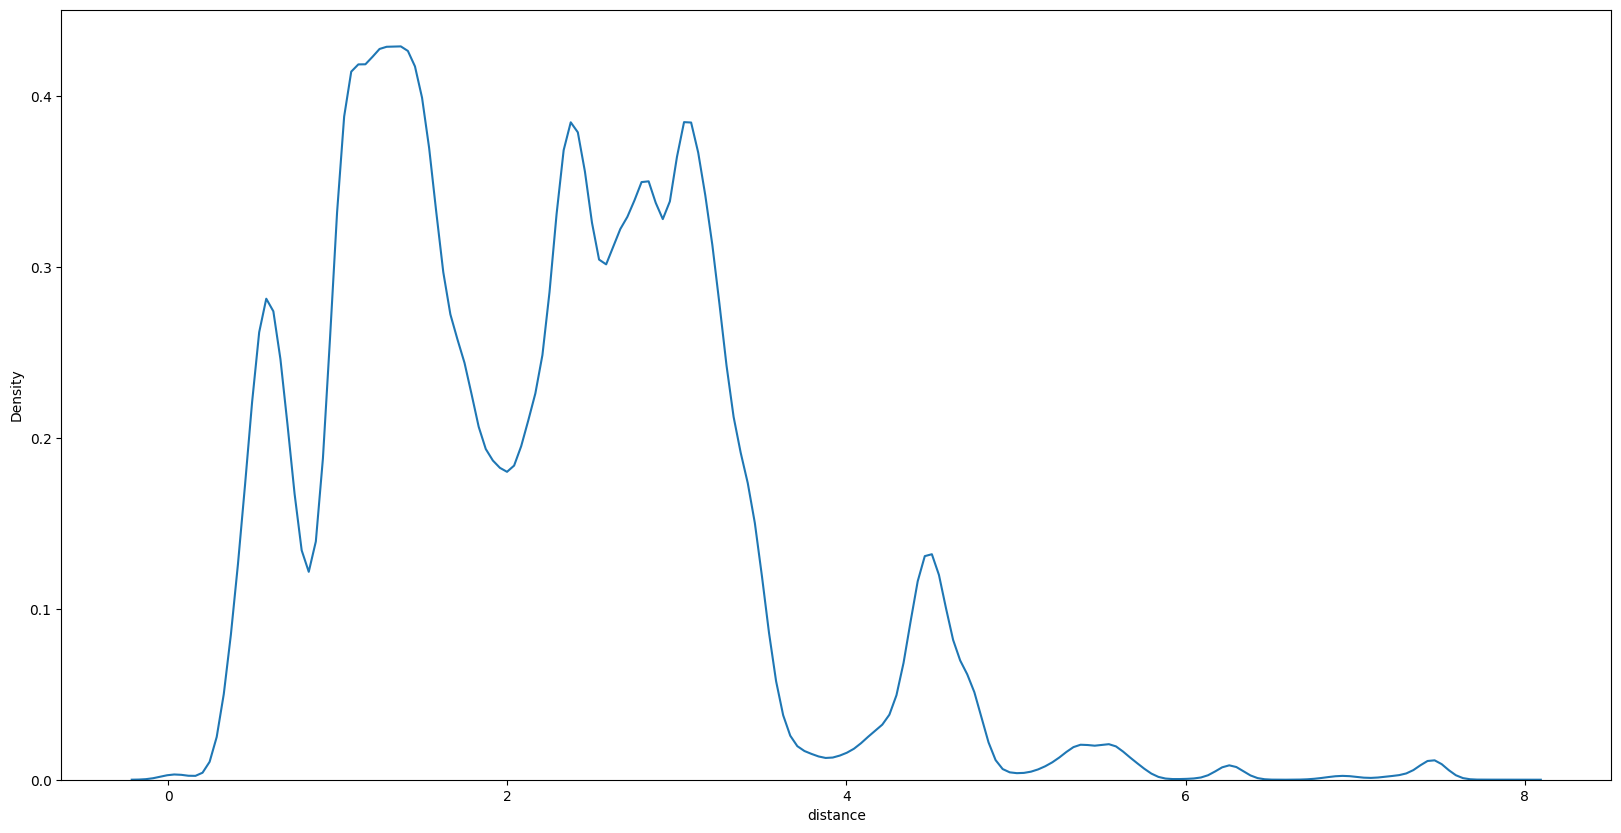

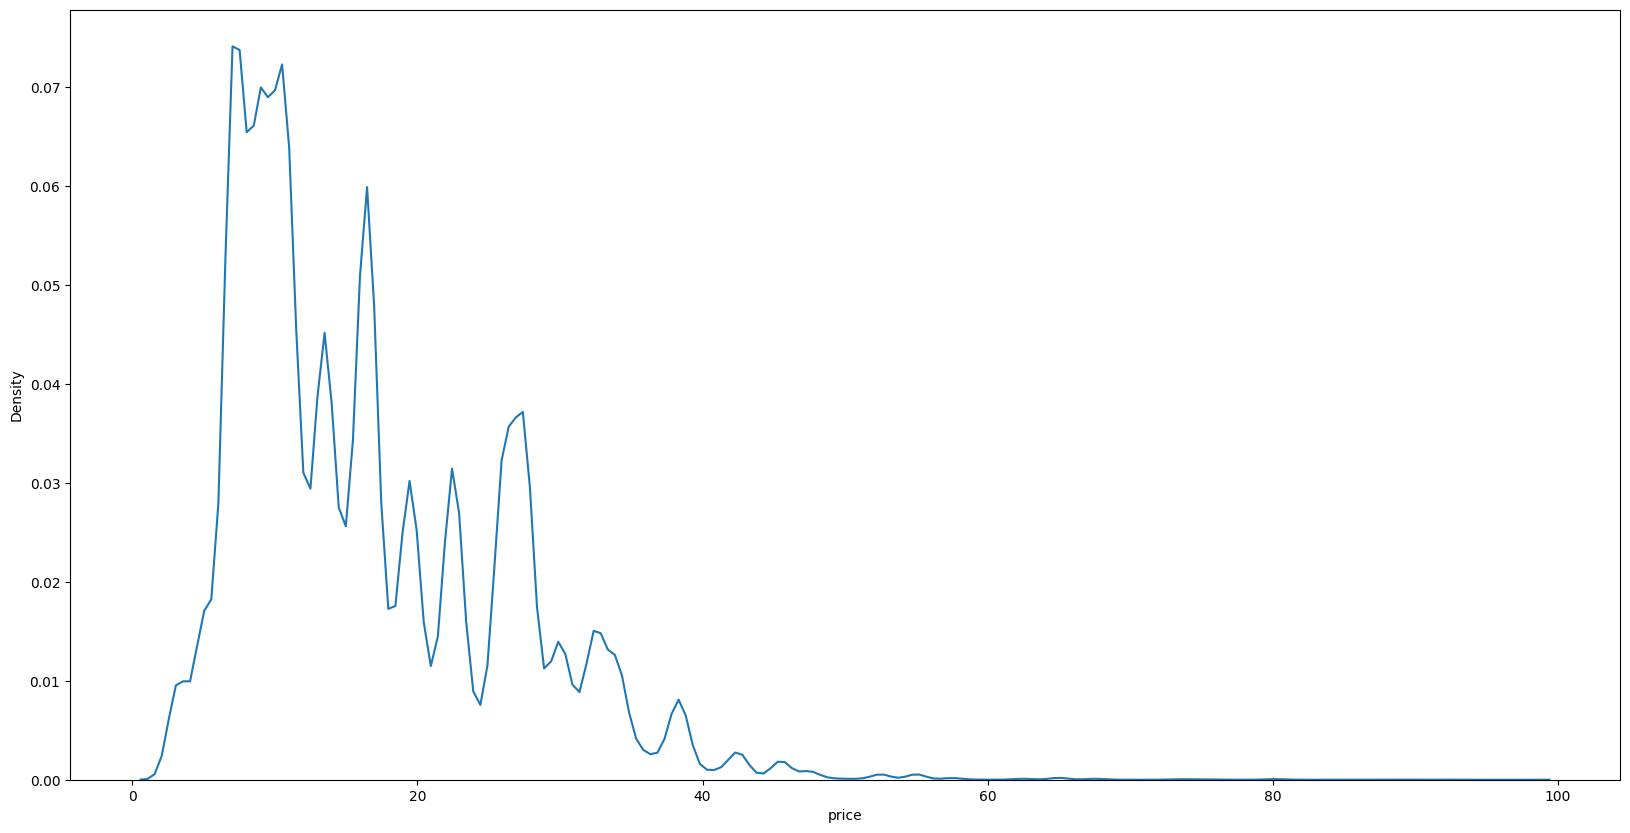

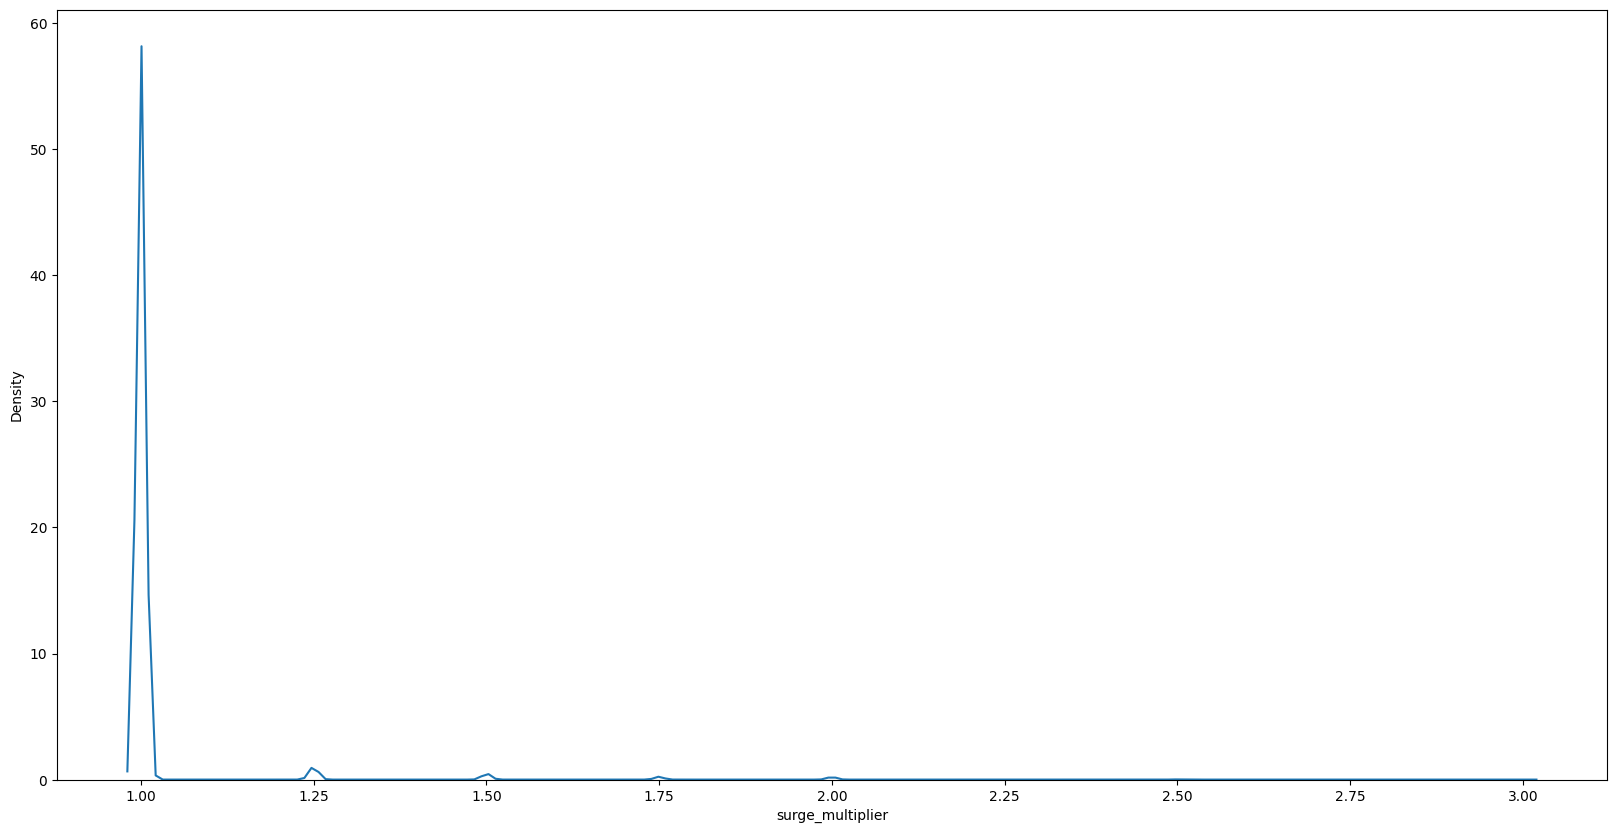

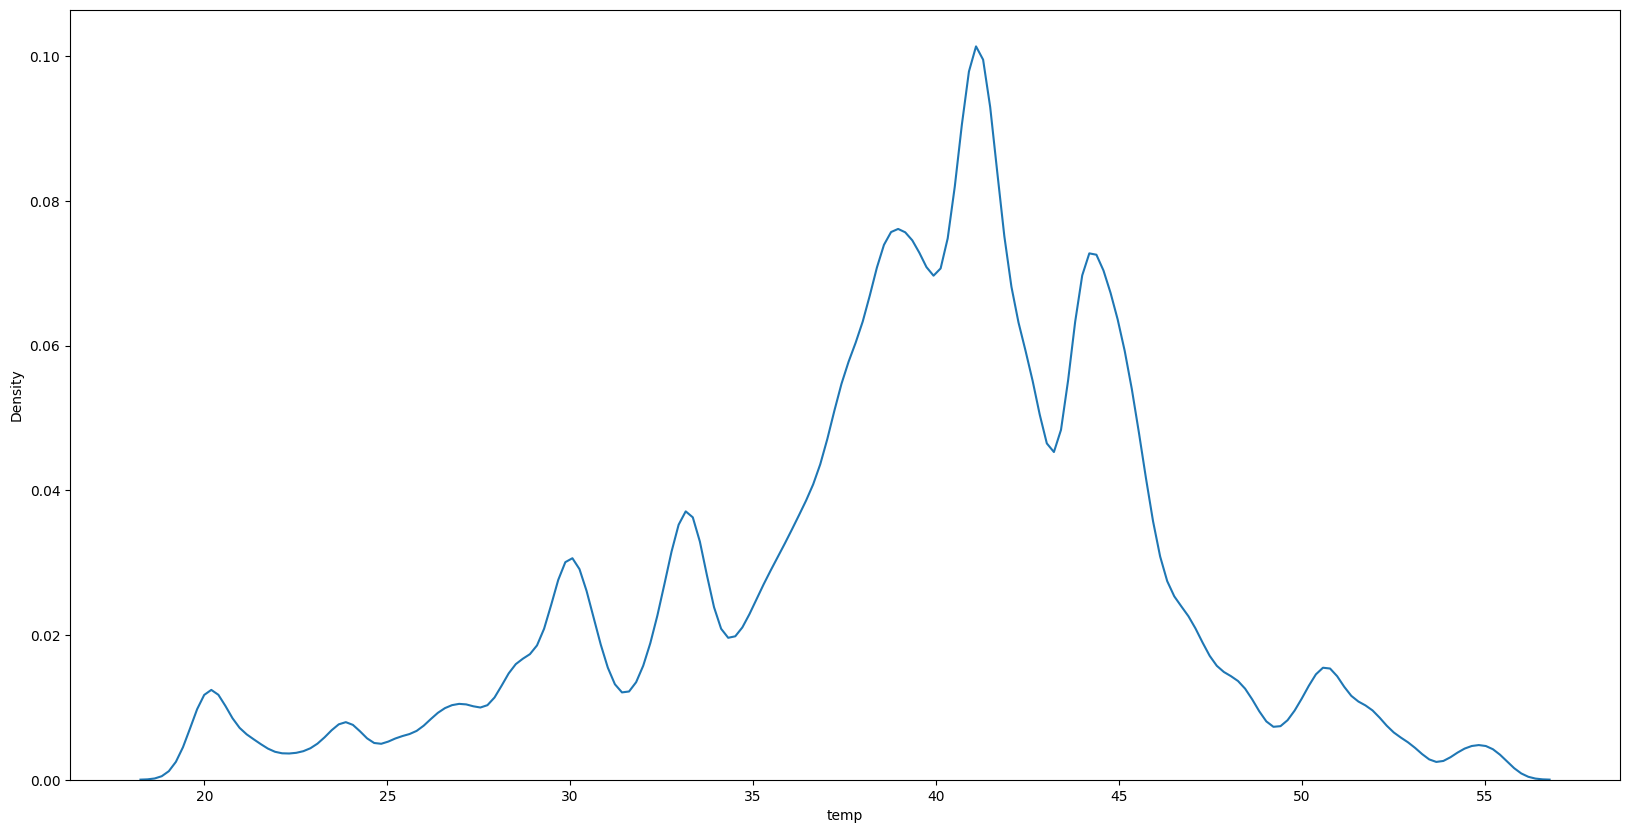

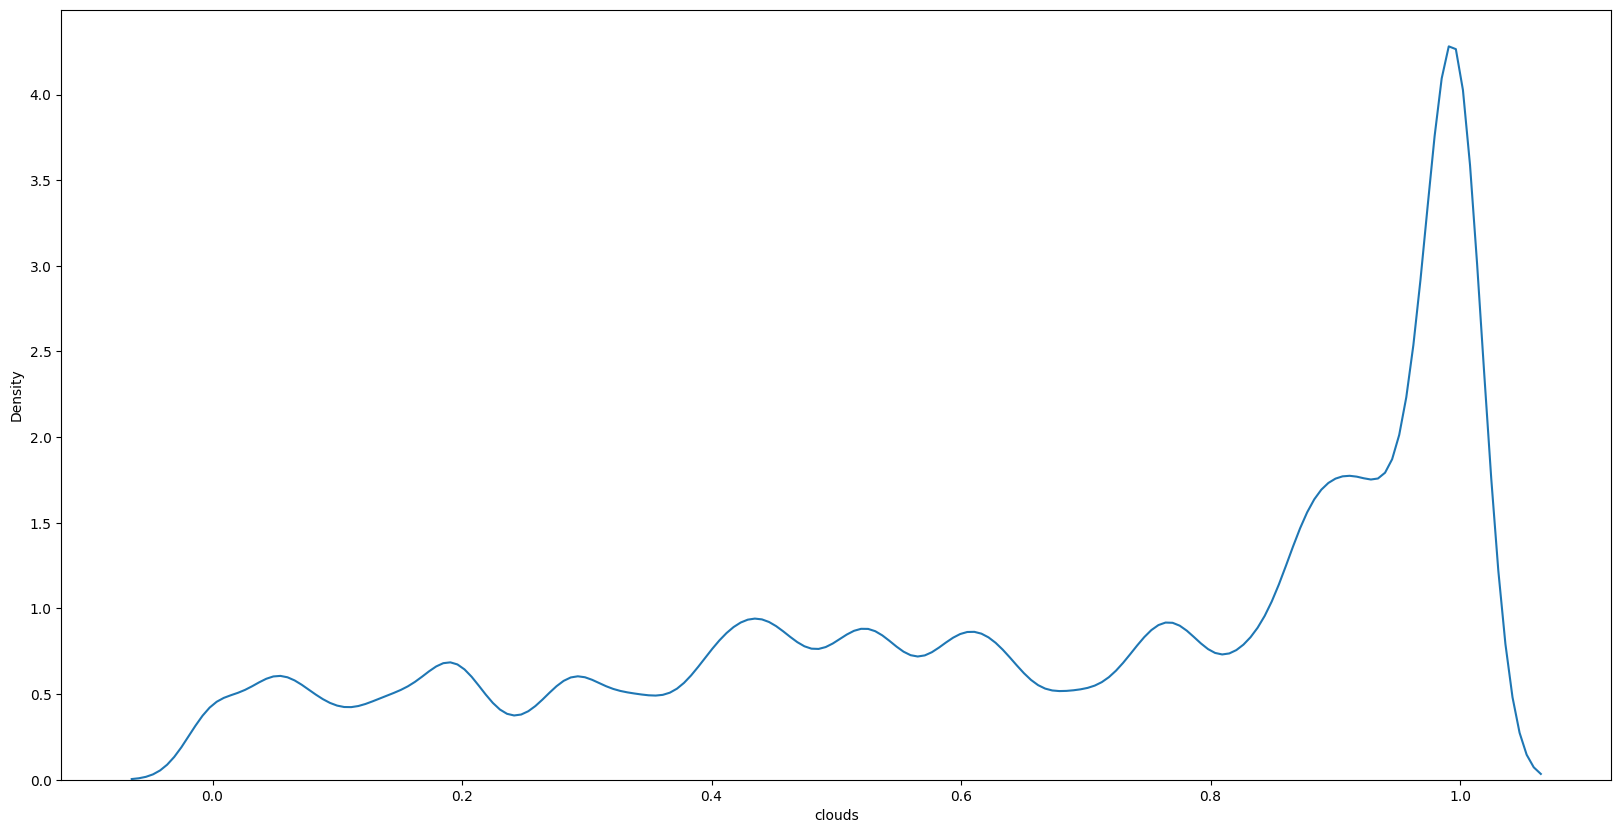

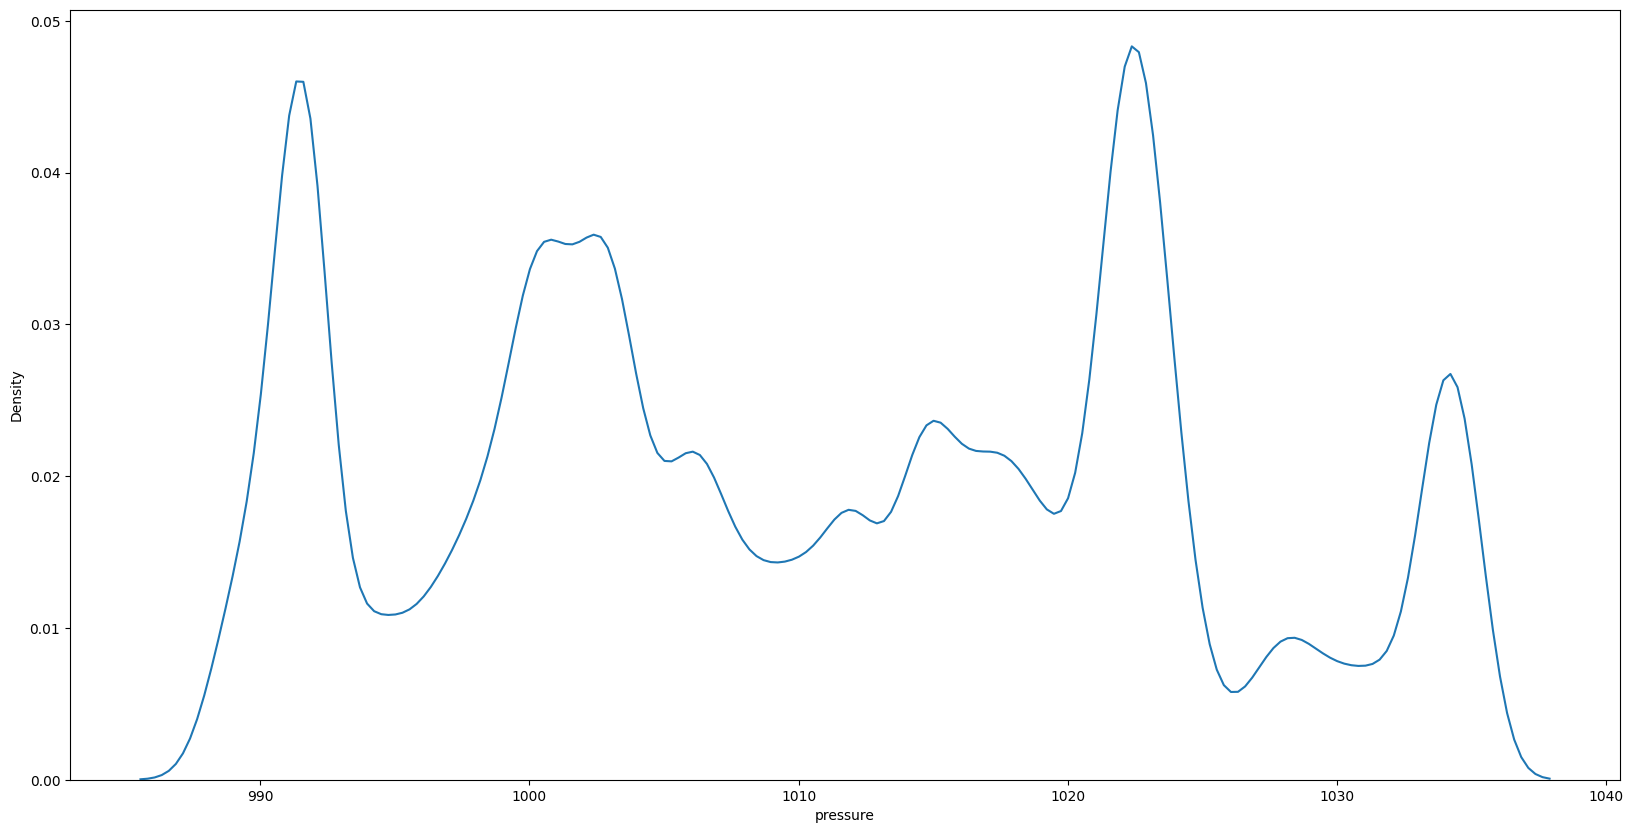

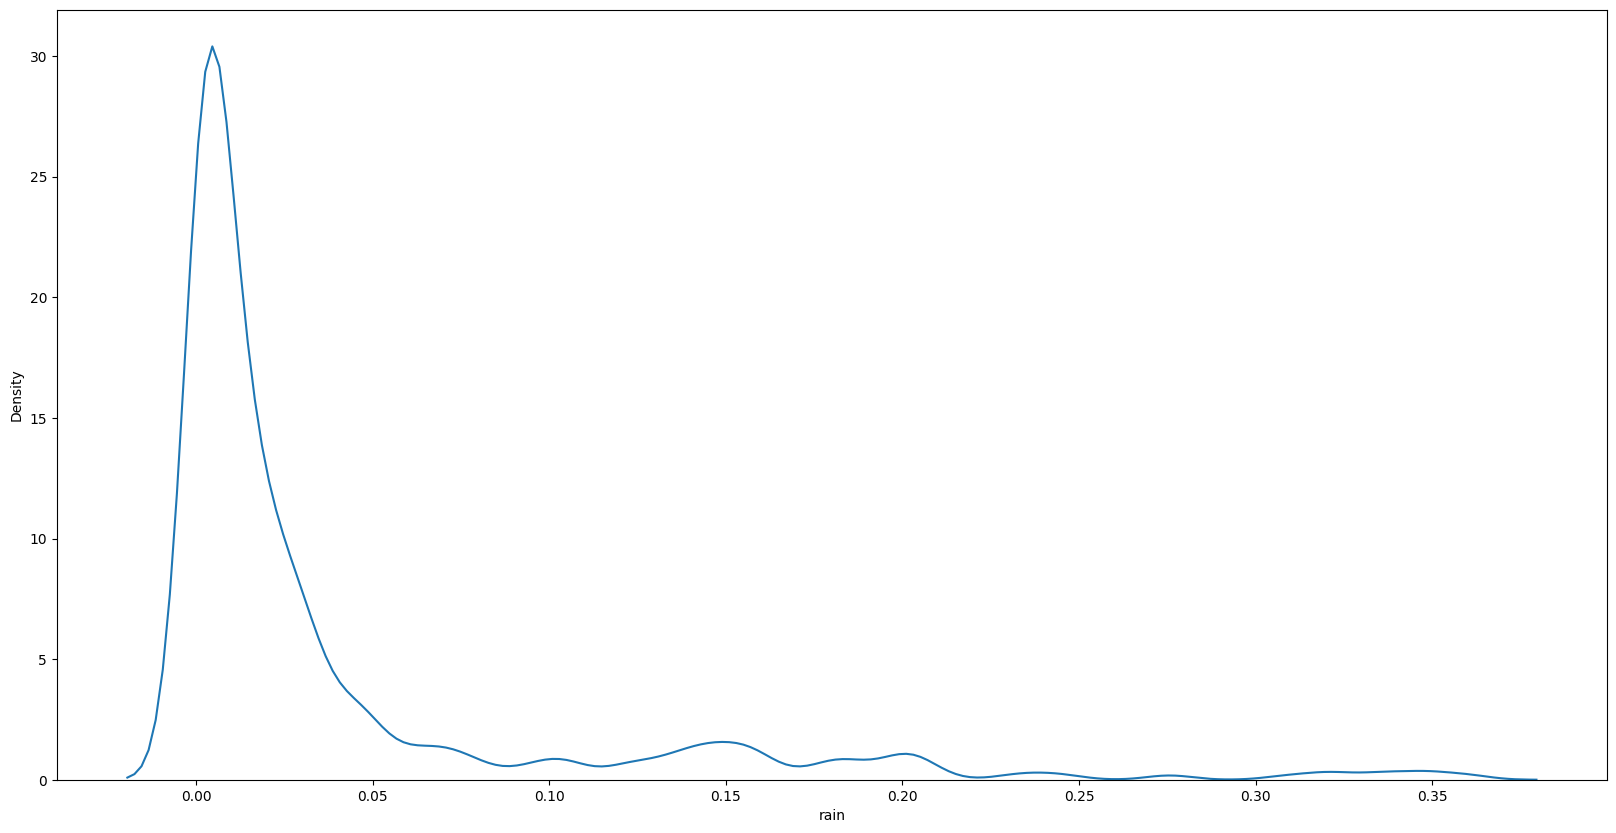

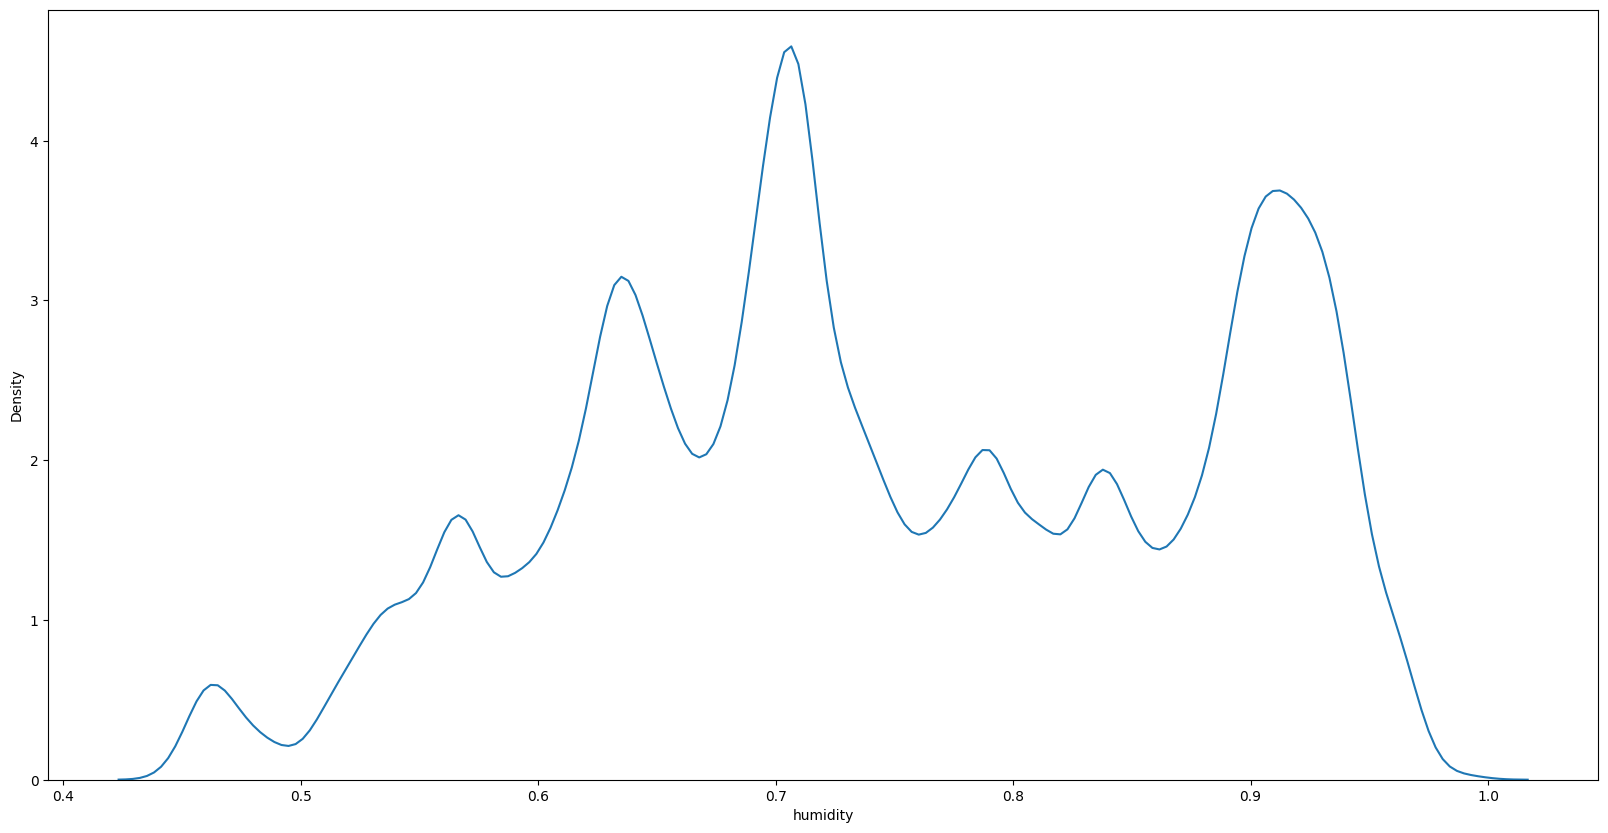

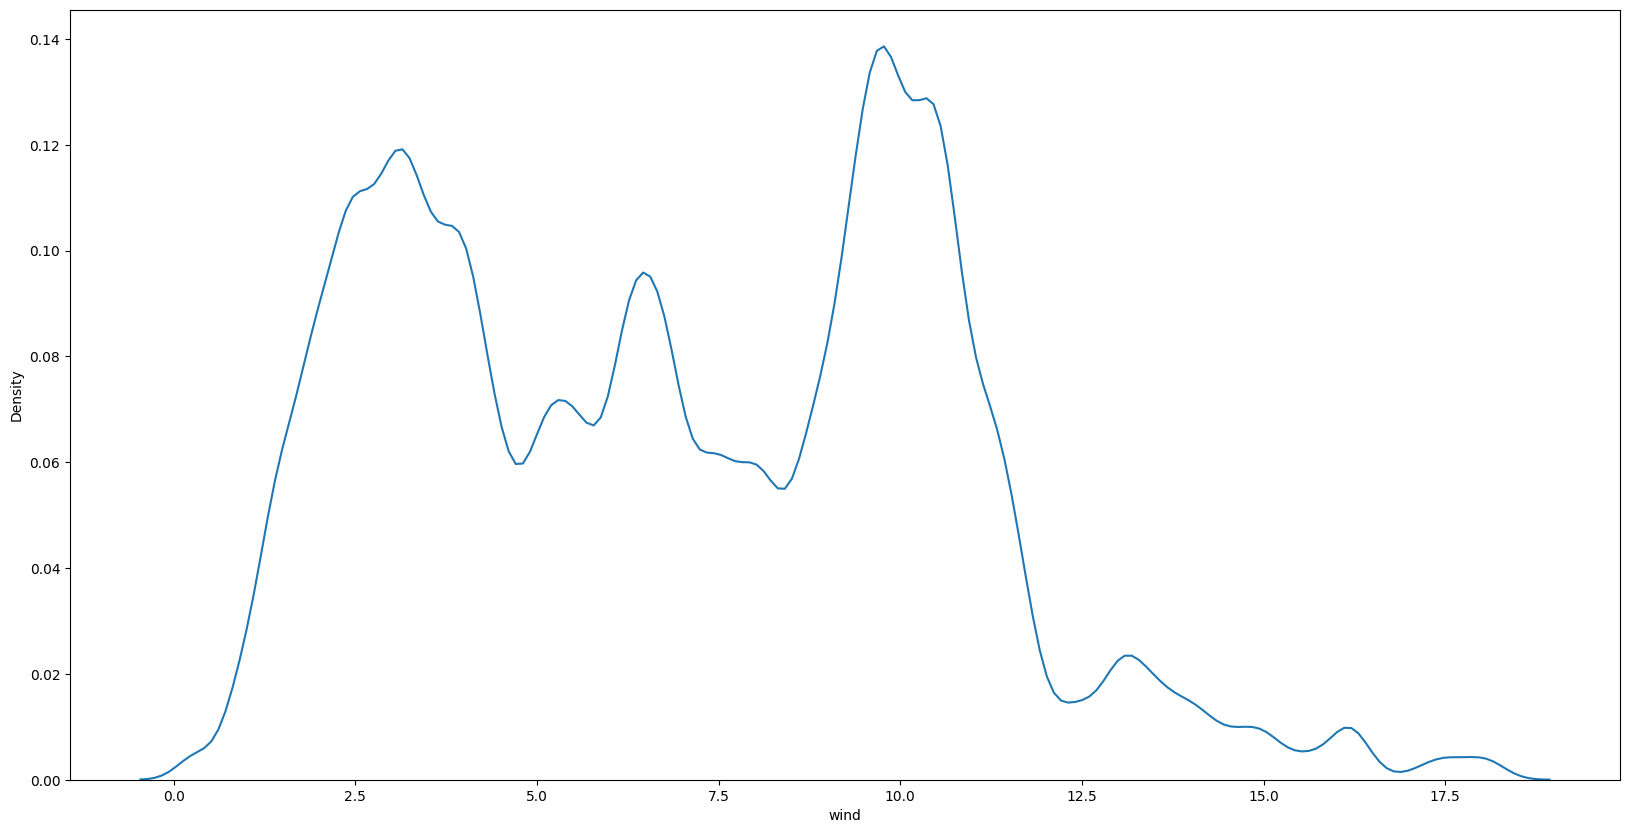

In [60]:
for i in quantative_columns:
    plt.figure(figsize=(20,10))
    s.kdeplot(x = i,data=merged_df)

================================================== qq_plot of : distance ==================================================


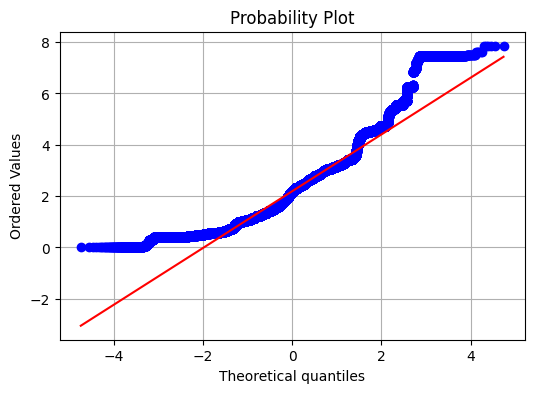

================================================== qq_plot of : price ==================================================


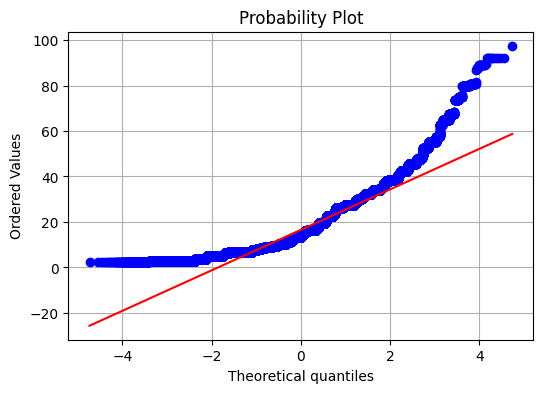

================================================== qq_plot of : surge_multiplier ==================================================


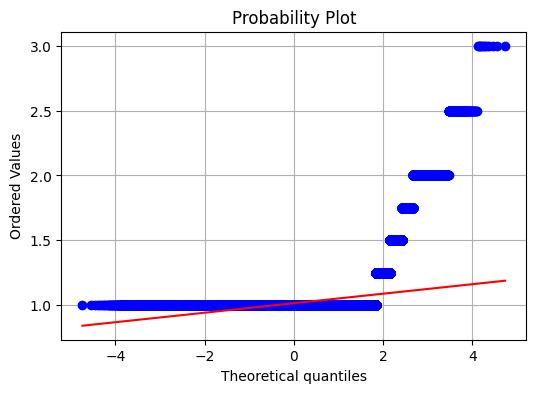

================================================== qq_plot of : temp ==================================================


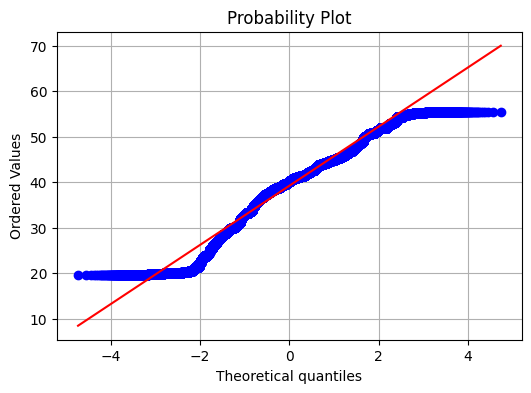

================================================== qq_plot of : clouds ==================================================


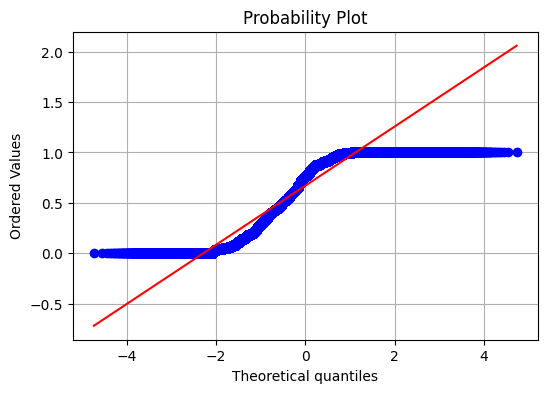

================================================== qq_plot of : pressure ==================================================


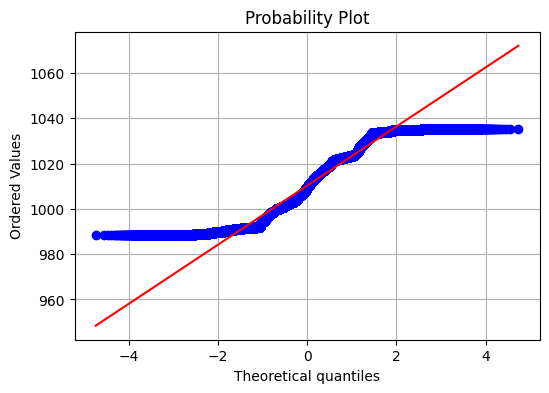

================================================== qq_plot of : rain ==================================================


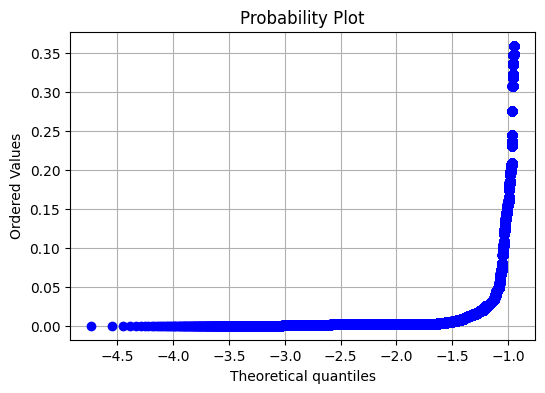

================================================== qq_plot of : humidity ==================================================


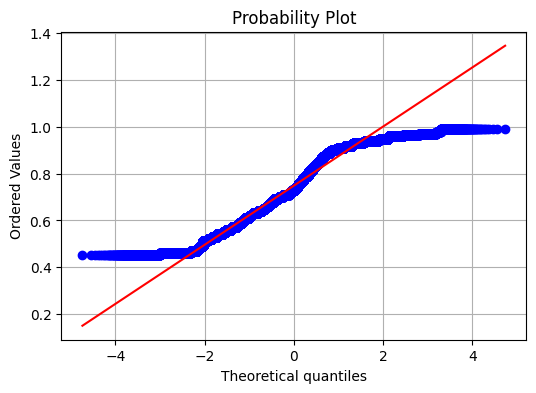

================================================== qq_plot of : wind ==================================================


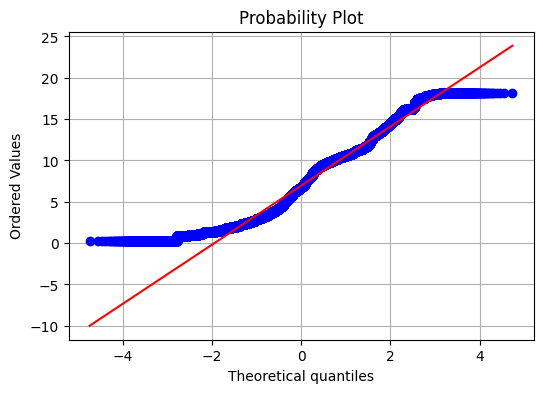

In [142]:
for i in quantative_columns:
    plt.figure(figsize=(6,4))
    print("="*50,f"qq_plot of : {i}","="*50)
    stats.probplot(merged_df[i],plot = plt)
    plt.grid(True)
    plt.show()

In [54]:
for i in quantative_columns:
    print("="*25,f"skive_ness of :{i}","="*25)
    print(merged_df[i].skew())

========================= skive_ness of :distance =========================
0.8173573026076867
========================= skive_ness of :price =========================
1.0456181723260864
========================= skive_ness of :surge_multiplier =========================
7.971911951009019
========================= skive_ness of :temp =========================
-0.6098486617768026
========================= skive_ness of :clouds =========================
-0.6155270844759927
========================= skive_ness of :pressure =========================
0.14853021885605222
========================= skive_ness of :rain =========================
2.618243194277976
========================= skive_ness of :humidity =========================
-0.07598150058453136
========================= skive_ness of :wind =========================
0.27936931436683454


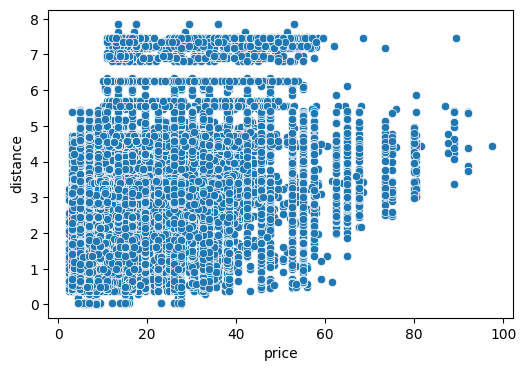

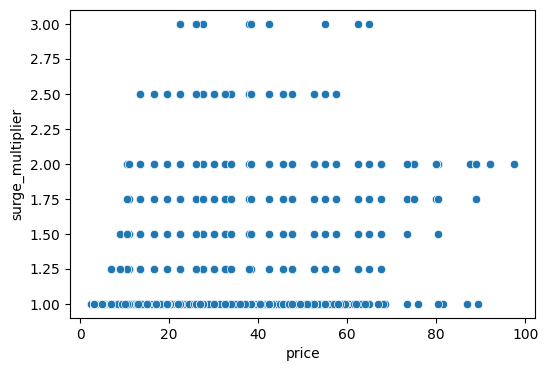

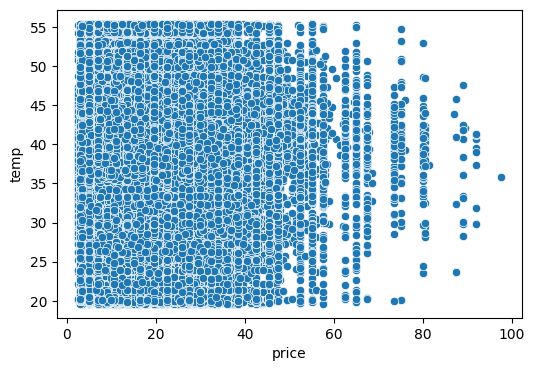

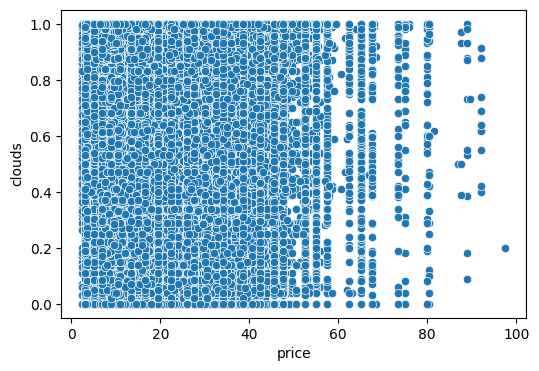

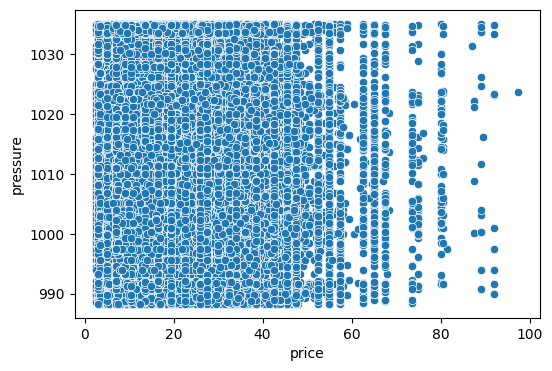

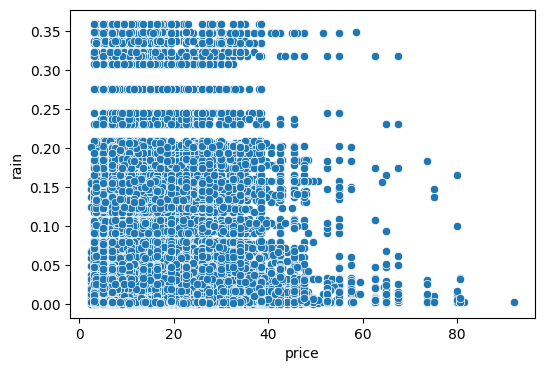

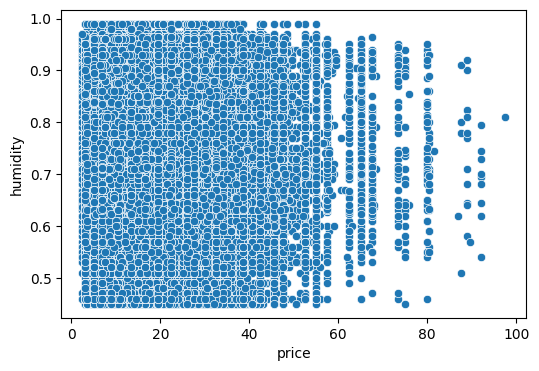

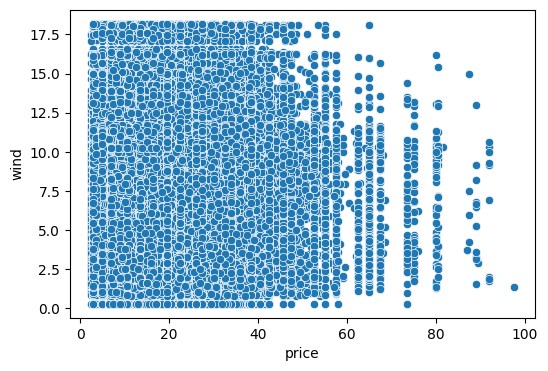

In [59]:
for i in quantative_columns:
    if i != "price":
        plt.figure(figsize=(6,4))
        s.scatterplot(x = "price",y=i,data=merged_df)

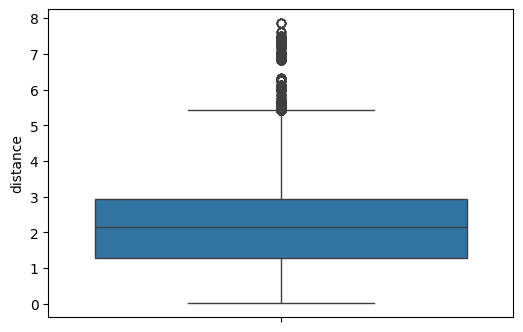

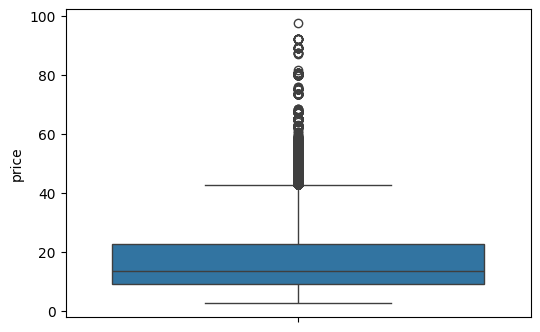

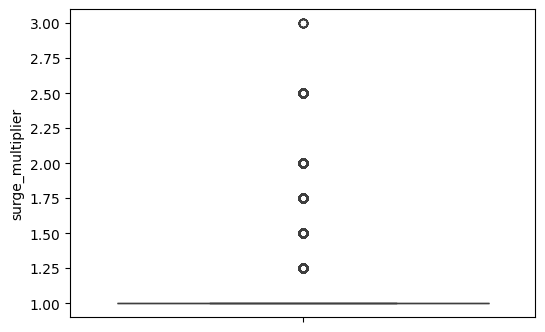

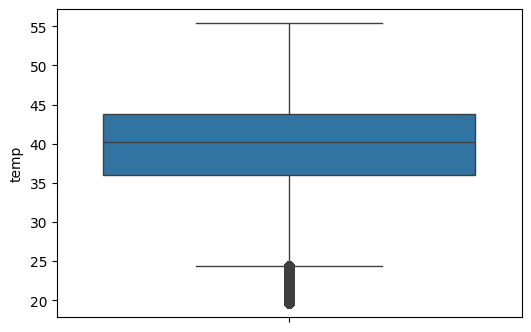

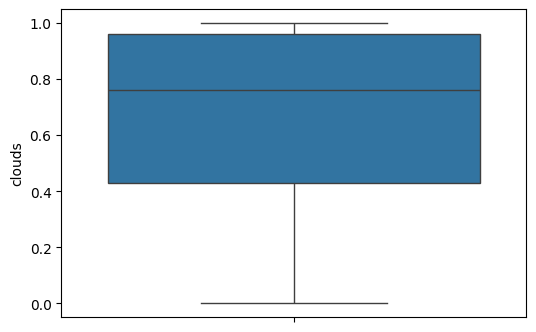

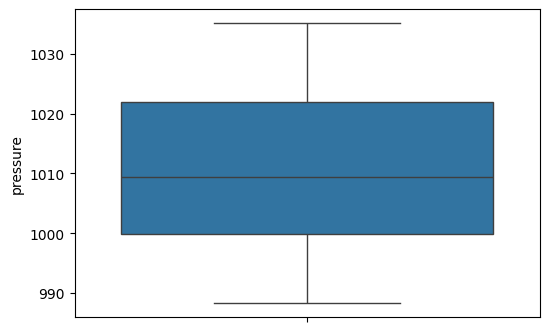

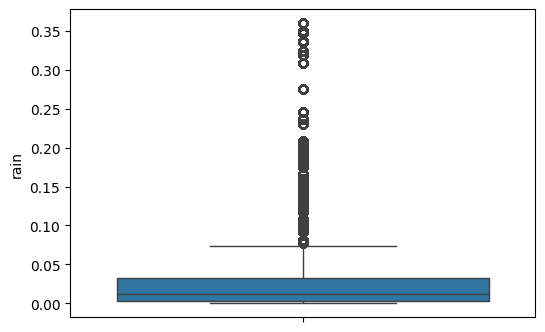

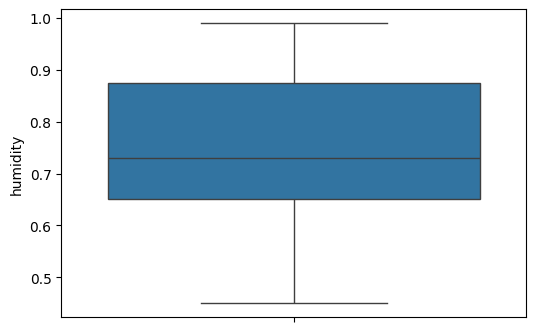

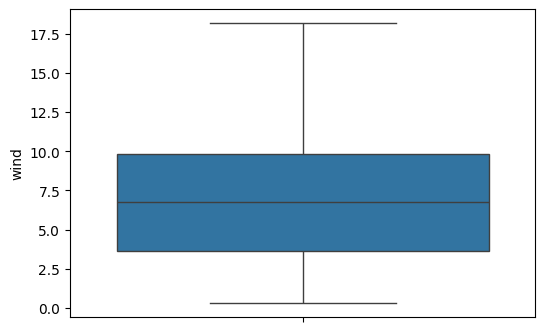

In [56]:
for i in quantative_columns:
    plt.figure(figsize=(6,4))
    s.boxplot(y = i,data=merged_df)
    plt.show()

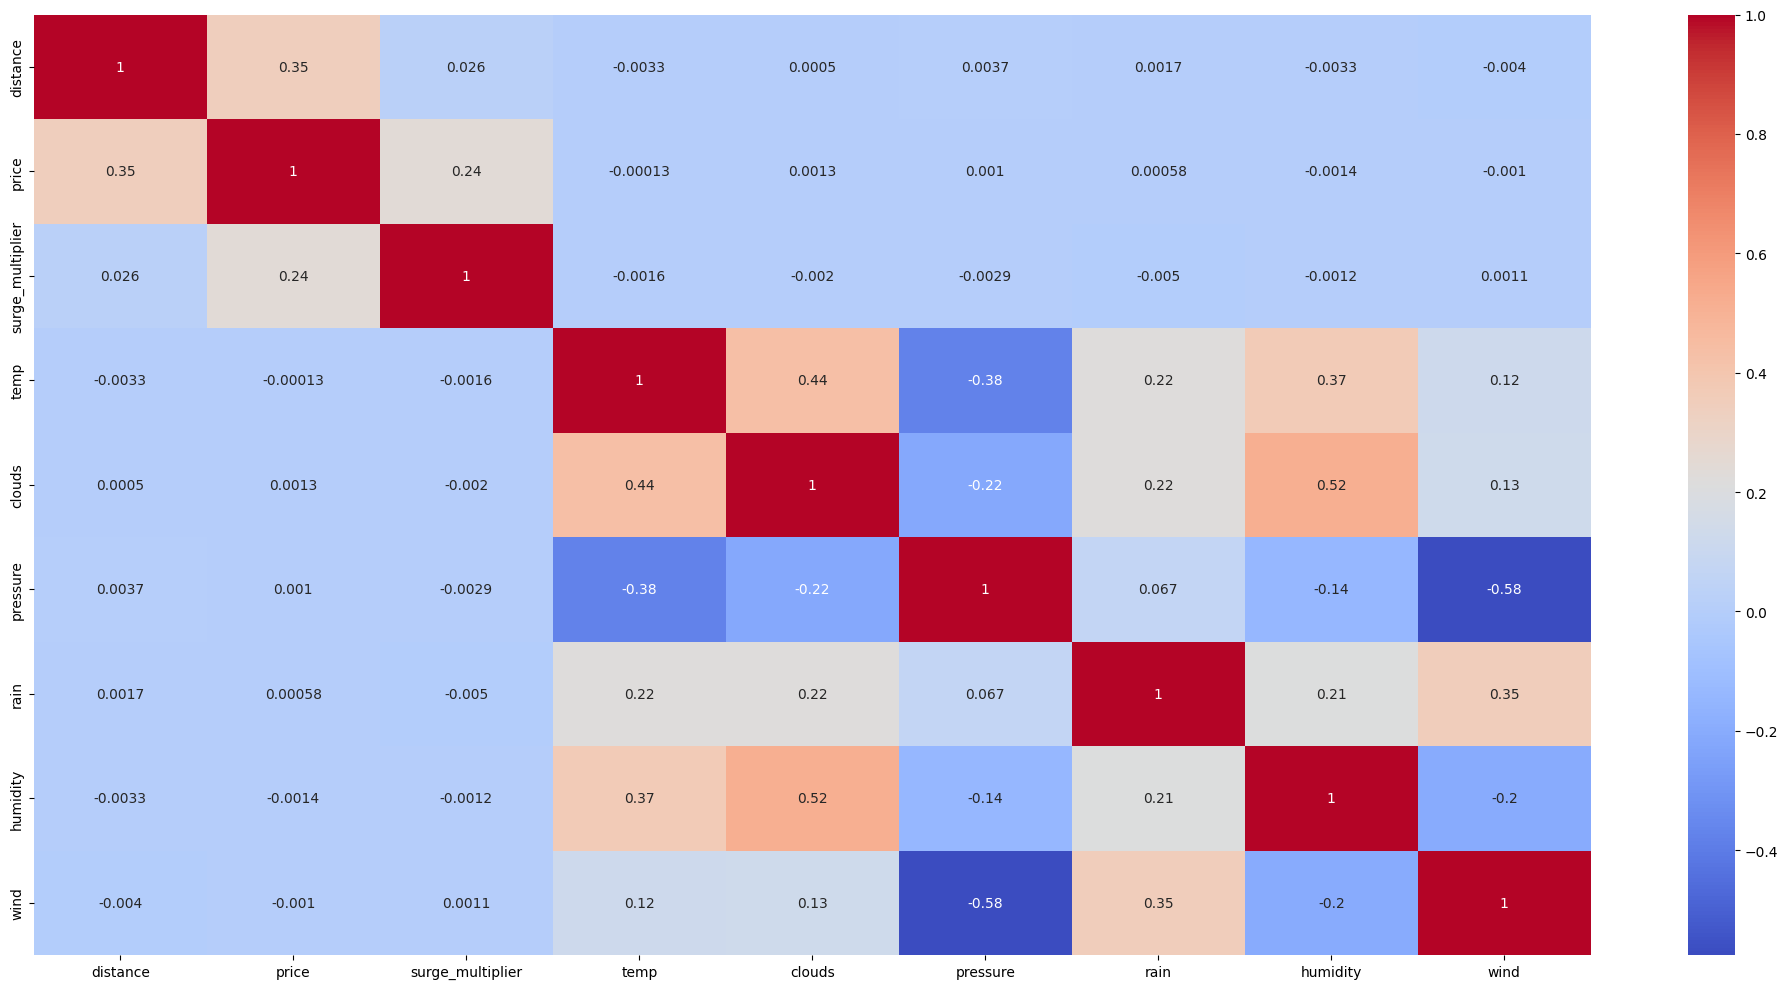

In [146]:
plt.figure(figsize=(20,10))
s.heatmap(merged_df.corr(numeric_only=True),annot=True,cmap="coolwarm")
plt.tight_layout()

In [57]:
merged_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 635242 entries, 0 to 693070
Data columns (total 15 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   distance          635242 non-null  float64       
 1   cab_type          635242 non-null  object        
 2   destination       635242 non-null  object        
 3   source            635242 non-null  object        
 4   price             635242 non-null  float64       
 5   surge_multiplier  635242 non-null  float64       
 6   name              635242 non-null  object        
 7   date_time         635242 non-null  datetime64[ns]
 8   hour_date         635242 non-null  datetime64[ns]
 9   temp              635242 non-null  float64       
 10  clouds            635242 non-null  float64       
 11  pressure          635242 non-null  float64       
 12  rain              109152 non-null  float64       
 13  humidity          635242 non-null  float64       
 14  wind     

In [58]:
merged_df

,distance,cab_type,destination,source,price,surge_multiplier,name,date_time,hour_date,temp,clouds,pressure,rain,humidity,wind
0,0.44,Lyft,North Station,Haymarket Square,5.0,1.0,Shared,2018-12-16 09:30:07.890,2018-12-16 09:00:00,38.460,0.290000,1022.25,NaN,0.760000,7.68
1,0.44,Lyft,North Station,Haymarket Square,11.0,1.0,Lux,2018-11-27 02:00:23.677,2018-11-27 02:00:00,44.065,0.995000,1002.88,0.106,0.895000,12.63
3,0.44,Lyft,North Station,Haymarket Square,26.0,1.0,Lux Black XL,2018-11-30 04:53:02.749,2018-11-30 04:00:00,35.080,0.000000,1013.71,NaN,0.700000,5.25
4,0.44,Lyft,North Station,Haymarket Square,9.0,1.0,Lyft XL,2018-11-29 03:49:20.223,2018-11-29 03:00:00,37.680,0.433333,998.42,NaN,0.706667,11.16
5,0.44,Lyft,North Station,Haymarket Square,16.5,1.0,Lux Black,2018-12-17 18:25:12.138,2018-12-17 18:00:00,40.780,0.930000,1000.15,NaN,0.790000,7.55
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
693065,1.00,Uber,North End,West End,9.5,1.0,WAV,2018-12-01 23:53:05.534,2018-12-01 23:00:00,36.690,0.410000,1023.64,NaN,0.760000,2.51
693066,1.00,Uber,North End,West End,13.0,1.0,UberXL,2018-12-01 23:53:05.534,2018-12-01 23:00:00,36.690,0.410000,1023.64,NaN,0.760000,2.51
693067,1.00,Uber,North End,West End,9.5,1.0,UberX,2018-12-01 23:53:05.534,2018-12-01 23:00:00,36.690,0.410000,1023.64,NaN,0.760000,2.51
693069,1.00,Uber,North End,West End,27.0,1.0,Black SUV,2018-12-01 23:53:05.534,2018-12-01 23:00:00,36.690,0.410000,1023.64,NaN,0.760000,2.51


In [34]:
x = merged_df.drop(columns="price", axis = 1)
y = merged_df["price"]

In [35]:
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import*
from sklearn.impute import*

In [36]:
x_train,x_test,y_train,y_test = train_test_split(x, y, test_size=0.20, random_state=42)

In [37]:
x_train["surge_multiplier"].unique()

array([1.  , 1.5 , 1.25, 2.5 , 1.75, 2.  , 3.  ])

In [38]:
cab_tier_order = [[
    'Shared',        # Lowest Tier (Lyft Shared)
    'UberPool',      # Shared Uber
    'Lyft',          # Standard Regular Lyft
    'UberX',         # Standard Regular Uber
    'WAV',           # Wheelchair Accessible Vehicle (Same fare as UberX)
    'Lyft XL',       # Large Vehicle Lyft
    'UberXL',        # Large Vehicle Uber
    'Lux',           # Premium Sedan (Lyft)
    'Black',         # Premium Sedan (Uber)
    'Lux Black',     # Luxury Sedan (Lyft)
    'Lux Black XL',  # Ultra Luxury SUV (Lyft)
    'Black SUV'      # Ultra Luxury SUV (Uber)
]]

## 10. Data Preprocessing

Data preprocessing prepares the dataset before it is used to train machine learning models.

Categorical features need to be converted into a numerical format, while numerical features may require scaling depending on their distribution and the preprocessing method used.

The preprocessing steps are applied to make the data suitable for model training and evaluation.

In [39]:
from project.transformer import DateTimeFeatureTransformer

In [40]:
trf = DateTimeFeatureTransformer()
trf.set_output(transform="pandas")

DateTimeFeatureTransformer()

In [41]:
trf1 = ColumnTransformer(transformers=[
    ("fill",SimpleImputer(add_indicator=True,fill_value=0,strategy="constant"),["rain"]),
    ("oe",OrdinalEncoder(categories=cab_tier_order,handle_unknown="use_encoded_value",unknown_value=-1),["name"]),
    ("ohe",OneHotEncoder(sparse_output=False,drop="first",handle_unknown='ignore'),["cab_type", "destination", "source"])
    
],
remainder="passthrough",
verbose_feature_names_out=False
)

In [42]:
trf1.set_output(transform="pandas")

,transformers,"[('fill', ...), ('oe', ...), ...]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,False
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'constant'
,fill_value,0


In [43]:
trf2 = ColumnTransformer(transformers=[
    ("pt",PowerTransformer(standardize=False,method='yeo-johnson'),["distance", "surge_multiplier", "rain"])
],
remainder="passthrough",
verbose_feature_names_out=False
)

In [44]:
trf2.set_output(transform="pandas")

,transformers,"[('pt', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,False
,force_int_remainder_cols,'deprecated'
,method,'yeo-johnson'
,standardize,False
,copy,True


In [45]:
trf3 = ColumnTransformer(transformers=[
    ("rs",RobustScaler(),["distance", "surge_multiplier", "temp", "rain"]),
    ("std",StandardScaler(),["clouds", "pressure", "humidity", "wind"])
],
remainder="passthrough",
verbose_feature_names_out=False    
)

In [46]:
trf3.set_output(transform="pandas")

,transformers,"[('rs', ...), ('std', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,False
,force_int_remainder_cols,'deprecated'
,with_centering,True
,with_scaling,True
,quantile_range,"(25.0, ...)"


In [47]:
from sklearn.pipeline import Pipeline
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectFromModel
from sklearn.ensemble import ExtraTreesRegressor
from xgboost import XGBRegressor
from sklearn.linear_model import*
from sklearn.tree import DecisionTreeRegressor
from lightgbm import LGBMRegressor
from sklearn.ensemble import RandomForestRegressor

In [48]:
# feature_selector = SelectFromModel(
#     estimator=ExtraTreesRegressor(
#         n_estimators=200,
#         random_state=42,
#         n_jobs=-1
#     ),
#     threshold="median"
# )

In [108]:
final_pipeline = Pipeline([
    ("date_time_fetures",DateTimeFeatureTransformer()),
    ("tf1", trf1),
    ("tf2", trf2),
    ("tf3", trf3),
    ("model", XGBRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=8,
        min_child_weight=2,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    ))
])
final_pipeline.set_output(transform="pandas")

,steps,"[('date_time_fetures', ...), ('tf1', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('fill', ...), ('oe', ...), ...]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,False


In [109]:
# final_pipeline = Pipeline([
#     ("tf1", trf1),
#     ("tf2", trf2),
#     ("tf3", trf3),
#     ("feature_selection", feature_selector),
#     ("model",LinearRegression())
# ])
# final_pipeline.set_output(transform="pandas")

In [110]:
# final_pipeline = Pipeline([
#     ("tf1", trf1),
#     ("tf2", trf2),
#     ("tf3", trf3),
#     ("feature_selection", feature_selector),
#     ("model",Ridge(alpha=1.0))
# ])
# final_pipeline.set_output(transform="pandas")

#r2 = 0.8322294929058415

In [111]:
# final_pipeline = Pipeline([
#     ("tf1", trf1),
#     ("tf2", trf2),
#     ("tf3", trf3),
#     ("feature_selection", feature_selector),
#     ("model",LGBMRegressor(
#         n_estimators=100,
#         learning_rate=0.05,
#         max_depth=-1,
#         random_state=42,
#         verbosity=-1
#     ))
# ])
# final_pipeline.set_output(transform="pandas")

In [112]:
# final_pipeline = Pipeline([
#     ("tf1", trf1),
#     ("tf2", trf2),
#     ("tf3", trf3),
#     ("feature_selection", feature_selector),
#     ("model",RandomForestRegressor(
#         n_estimators=100,
#         random_state=42,
#         n_jobs=-1
#     ))
# ])
# final_pipeline.set_output(transform="pandas")

In [ ]:
final_pipeline.fit(x_train, y_train)

In [104]:
from sklearn.metrics import r2_score

In [105]:
y_pred = final_pipeline.predict(x_test)

In [106]:
y_pred = final_pipeline.predict(x_test)

r2_score(y_test, y_pred)

0.9620951545960181

In [107]:
y_train_pred = final_pipeline.predict(x_train)

train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_pred)

print("Train R²:", train_r2)
print("Test R² :", test_r2)

Train R²: 0.9712680388920905
Test R² : 0.9620951545960181


In [60]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5

print("MAE :", mae)
print("RMSE:", rmse)
print("R²  :", test_r2)

MAE : 1.1264883234538998
RMSE: 1.8290891930318913
R²  : 0.9616304404479172


In [61]:
# from sklearn.model_selection import KFold, cross_val_score

# cv = KFold(
#     n_splits=5,
#     shuffle=True,
#     random_state=42
# )

# scores = cross_val_score(
#     final_pipeline,
#     x_train,
#     y_train,
#     cv=cv,
#     scoring="r2",
#     n_jobs=1
# )

# print("Fold Scores:", scores)
# print("Mean CV R²:", scores.mean())
# print("Std CV R²:", scores.std())

In [62]:
X_selected = final_pipeline[:-1].transform(x_train)

print("Final number of features:", X_selected.shape[1])
print(X_selected.columns.tolist())

Final number of features: 41
['distance', 'surge_multiplier', 'temp', 'rain', 'clouds', 'pressure', 'humidity', 'wind', 'missingindicator_rain', 'name', 'cab_type_Uber', 'destination_Beacon Hill', 'destination_Boston University', 'destination_Fenway', 'destination_Financial District', 'destination_Haymarket Square', 'destination_North End', 'destination_North Station', 'destination_Northeastern University', 'destination_South Station', 'destination_Theatre District', 'destination_West End', 'source_Beacon Hill', 'source_Boston University', 'source_Fenway', 'source_Financial District', 'source_Haymarket Square', 'source_North End', 'source_North Station', 'source_Northeastern University', 'source_South Station', 'source_Theatre District', 'source_West End', 'hour', 'day_of_week', 'day', 'month', 'is_weekend', 'is_rush_hour', 'hour_sin', 'hour_cos']


In [84]:
x_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 508193 entries, 688978 to 133074
Data columns (total 14 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   distance          508193 non-null  float64       
 1   cab_type          508193 non-null  object        
 2   destination       508193 non-null  object        
 3   source            508193 non-null  object        
 4   surge_multiplier  508193 non-null  float64       
 5   name              508193 non-null  object        
 6   date_time         508193 non-null  datetime64[ns]
 7   hour_date         508193 non-null  datetime64[ns]
 8   temp              508193 non-null  float64       
 9   clouds            508193 non-null  float64       
 10  pressure          508193 non-null  float64       
 11  rain              87348 non-null   float64       
 12  humidity          508193 non-null  float64       
 13  wind              508193 non-null  float64       
dtypes: d

In [85]:
import pickle

with open("fare_prediction_pipeline.pkl", "wb") as file:
    pickle.dump(final_pipeline, file)

print("Model saved successfully!")

Model saved successfully!
